# QF603 time-series extension (Parts 1 and 2)

**Folder must contain only:** this notebook + `tri_full_panel_14assets.csv` + `tri_full_panel_10sectors.csv`.

**How to run:** press **Run All** at the top. (Needs numpy, pandas, scipy, matplotlib.) A folder `results` is created with all charts and tables.

**Two questions this notebook answers**
1. **Part 1:** does yesterday's return help predict today's? Is there any pattern to harvest?
2. **Part 2:** do wild days come in clusters (volatility clustering), and does a GARCH volatility label agree with our project's `vol_regime`?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize
from scipy.signal import lfilter
import matplotlib.pyplot as plt
%matplotlib inline

HERE = Path.cwd()          # the folder this notebook is in (put the 2 CSVs here)
RESULTS = HERE / "results"
RESULTS.mkdir(exist_ok = True)
BLUE, ORANGE = "#2a6fb0", "#d9622b"
MAX_LAG = 20


def own_history(series):
    # every ETF starts on its own day: use it from its first valid day
    return series.loc[series.first_valid_index():].dropna()


def acf(x, nlags):
    x = np.asarray(x, dtype = float)
    n = len(x)
    xd = x - x.mean()
    denom = np.sum(xd ** 2)
    return np.array([np.sum(xd[k:] * xd[: n - k]) / denom for k in range(1, nlags + 1)])


def pacf(x, nlags):
    rho = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    out = np.zeros(nlags)
    phi[1, 1] = rho[0]
    out[0] = rho[0]
    for k in range(2, nlags + 1):
        num = rho[k - 1] - np.sum(phi[k - 1, 1:k] * rho[k - 2::-1][: k - 1])
        den = 1 - np.sum(phi[k - 1, 1:k] * rho[: k - 1])
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        out[k - 1] = phi[k, k]
    return out


def ljung_box(rho, n, h):
    k = np.arange(1, h + 1)
    q = n * (n + 2) * np.sum(rho[:h] ** 2 / (n - k))
    return q, stats.chi2.sf(q, df = h)


def ar1_fit(y, x):
    """today = a + phi * yesterday. Returns phi, normal t, robust t (allows calm and wild days)."""
    n = len(y)
    xd = x - x.mean()
    sxx = np.sum(xd ** 2)
    phi = np.sum(xd * (y - y.mean())) / sxx
    e = y - (y.mean() - phi * x.mean()) - phi * x
    t_normal = phi / np.sqrt(np.sum(e ** 2) / (n - 2) / sxx)
    t_robust = phi / np.sqrt(np.sum(xd ** 2 * e ** 2) / sxx ** 2 * n / (n - 2))
    return phi, t_normal, t_robust


def adf_stat(y, lags = 5):
    """Augmented Dickey-Fuller t-stat (with constant)."""
    y = np.asarray(y, dtype = float)
    dy = np.diff(y)
    n = len(dy)
    cols = [np.ones(n - lags), y[lags:-1]] + [dy[lags - i: n - i] for i in range(1, lags + 1)]
    X = np.column_stack(cols)
    Y = dy[lags:]
    beta = np.linalg.lstsq(X, Y, rcond = None)[0]
    e = Y - X @ beta
    s2 = np.sum(e ** 2) / (len(Y) - X.shape[1])
    return beta[1] / np.sqrt(s2 * np.linalg.inv(X.T @ X)[1, 1])


def arch_lm(e, lags = 5):
    """ARCH test: are squared returns predictable from past squared returns?"""
    e2 = np.asarray(e, dtype = float) ** 2
    n = len(e2)
    Y = e2[lags:]
    X = np.column_stack([np.ones(n - lags)] + [e2[lags - i: n - i] for i in range(1, lags + 1)])
    beta = np.linalg.lstsq(X, Y, rcond = None)[0]
    r2 = 1 - np.sum((Y - X @ beta) ** 2) / np.sum((Y - Y.mean()) ** 2)
    return len(Y) * r2, stats.chi2.sf(len(Y) * r2, df = lags)


def garch11(r_pct):
    """GARCH(1,1):  h_t = omega + alpha * e_(t-1)^2 + beta * h_(t-1).  Input in percent."""
    r = np.asarray(r_pct, dtype = float)
    e = r - r.mean()
    v0 = e.var()

    def variance_path(w, a, b):
        return lfilter([1.0], [1.0, -b], np.concatenate(([v0], w + a * e[:-1] ** 2)))

    def nll(p):
        h = variance_path(p[0] * v0, p[1], p[2])
        return 1e10 if np.any(h <= 0) else 0.5 * np.sum(np.log(h) + e ** 2 / h)

    best = None
    for start in ([0.05, 0.08, 0.90], [0.02, 0.05, 0.93], [0.10, 0.15, 0.75]):
        res = minimize(nll, start, method = "SLSQP",
                       bounds = [(1e-6, 5.0), (0.0, 0.99), (0.0, 0.999)],
                       constraints = [{"type": "ineq", "fun": lambda p: 0.9999 - p[1] - p[2]}])
        if best is None or res.fun < best.fun:
            best = res
    w, a, b = best.x[0] * v0, best.x[1], best.x[2]
    h = variance_path(w, a, b)
    persistence = a + b
    stuck = persistence >= 0.9995        # model says "shocks never fade": half-life not trustworthy
    return {"alpha": a, "beta": b, "persistence": persistence,
            "half_life": np.nan if stuck else np.log(0.5) / np.log(persistence),
            "sigma": np.sqrt(h), "std_resid": e / np.sqrt(h)}


def vol_regime_label(r):
    """Our rebuild of the project's vol_regime: 21-day std / 252-day std, HIGH if above its expanding median."""
    ratio = r.rolling(21).std() / r.rolling(252).std()
    med = ratio.expanding(min_periods = 252).median()
    return pd.Series(np.where(ratio.notna() & med.notna(), (ratio > med).astype(float), np.nan), index = r.index)


def cohen_kappa(a, b):
    a, b = np.asarray(a).astype(int), np.asarray(b).astype(int)
    po = np.mean(a == b)
    pe = np.mean(a) * np.mean(b) + (1 - np.mean(a)) * (1 - np.mean(b))
    return po, (po - pe) / (1 - pe)

## Step 1 - Load the CSVs and compute daily log returns
log return = ln(today's price / yesterday's price). The yearly volatility printed is a sanity check: SHY (short bonds) should be tiny (about 1.5%), SLV/VNQ/QQQ large (about 27-32%).

In [2]:
returns_all = {}

for name in ["14assets", "10sectors"]:
    prices =\
    (
        pd
        .read_csv(HERE / f"tri_full_panel_{name}.csv", index_col = 0, parse_dates = True)
        .sort_index()
    )
    returns =\
    (
        np
        .log(prices)
        .diff()
        .iloc[1:]
    )
    returns_all[name] = returns

    print(f"\n===== {name}: {prices.shape[0]} days, {prices.shape[1]} ETFs, "
          f"{prices.index.min().date()} to {prices.index.max().date()} =====")
    yearly_vol =\
    (
        returns
        .std()
        .mul(np.sqrt(252) * 100)
        .round(1)
    )
    print("yearly volatility % (sanity check, should look like real ETFs):")
    print(yearly_vol.to_string())


===== 14assets: 8288 days, 14 ETFs, 1993-01-29 to 2025-12-31 =====
yearly volatility % (sanity check, should look like real ETFs):
DBC    19.2
EEM    27.0
EFA    20.8
GLD    17.7
HYG    11.0
IEF     6.8
IWM    24.0
LQD     8.4
QQQ    27.0
SHY     1.5
SLV    31.6
SPY    18.6
TLT    14.4
VNQ    28.7

===== 10sectors: 6798 days, 10 ETFs, 1998-12-22 to 2025-12-31 =====
yearly volatility % (sanity check, should look like real ETFs):
XLE     28.8
XLF     28.5
XLK     25.9
XLV     17.9
XLI     21.2
XLP     15.2
XLY     22.8
XLU     19.3
XLB     23.7
XLRE    20.6


## Step 2 - Part 1: ACF, PACF, Ljung-Box, AR(1)
**Idea:** if yesterday was +1%, what do we expect tomorrow to be?
- `acf_lag1` = correlation of today with yesterday. SPY about -0.08, so after +1% we expect about -0.08%. Negative = small bounce-back.
- **Ljung-Box** = one test for many past days together. Small p-value = some pattern exists.
- **AR(1) phi** = the same number from a fitted line. `AR1_t_robust` is the safer t-stat (allows calm and wild days). |t| > 1.96 = significant.


===== 14assets =====
       days  acf_lag1  pacf_lag1  lags_outside_band_of_20  LjungBox10_p  LjungBox20_p  AR1_phi    AR1_t  AR1_t_robust
DBC  5008.0   -0.0035    -0.0035                      2.0        0.9891        0.4016  -0.0035  -0.2500       -0.1869
EEM  5717.0   -0.1067    -0.1067                     11.0        0.0000        0.0000  -0.1067  -8.1106       -3.8075
EFA  6128.0   -0.0969    -0.0969                      6.0        0.0000        0.0000  -0.0969  -7.6162       -3.6834
GLD  5312.0   -0.0141    -0.0141                      2.0        0.7052        0.6871  -0.0141  -1.0262       -0.7386
HYG  4712.0    0.0023     0.0023                      8.0        0.0000        0.0000   0.0023   0.1612        0.0434
IEF  5896.0   -0.0278    -0.0278                      5.0        0.0063        0.0036  -0.0279  -2.1402       -1.6116
IWM  6437.0   -0.0659    -0.0659                      8.0        0.0000        0.0000  -0.0659  -5.2997       -3.0441
LQD  5896.0    0.0020     0.0020  

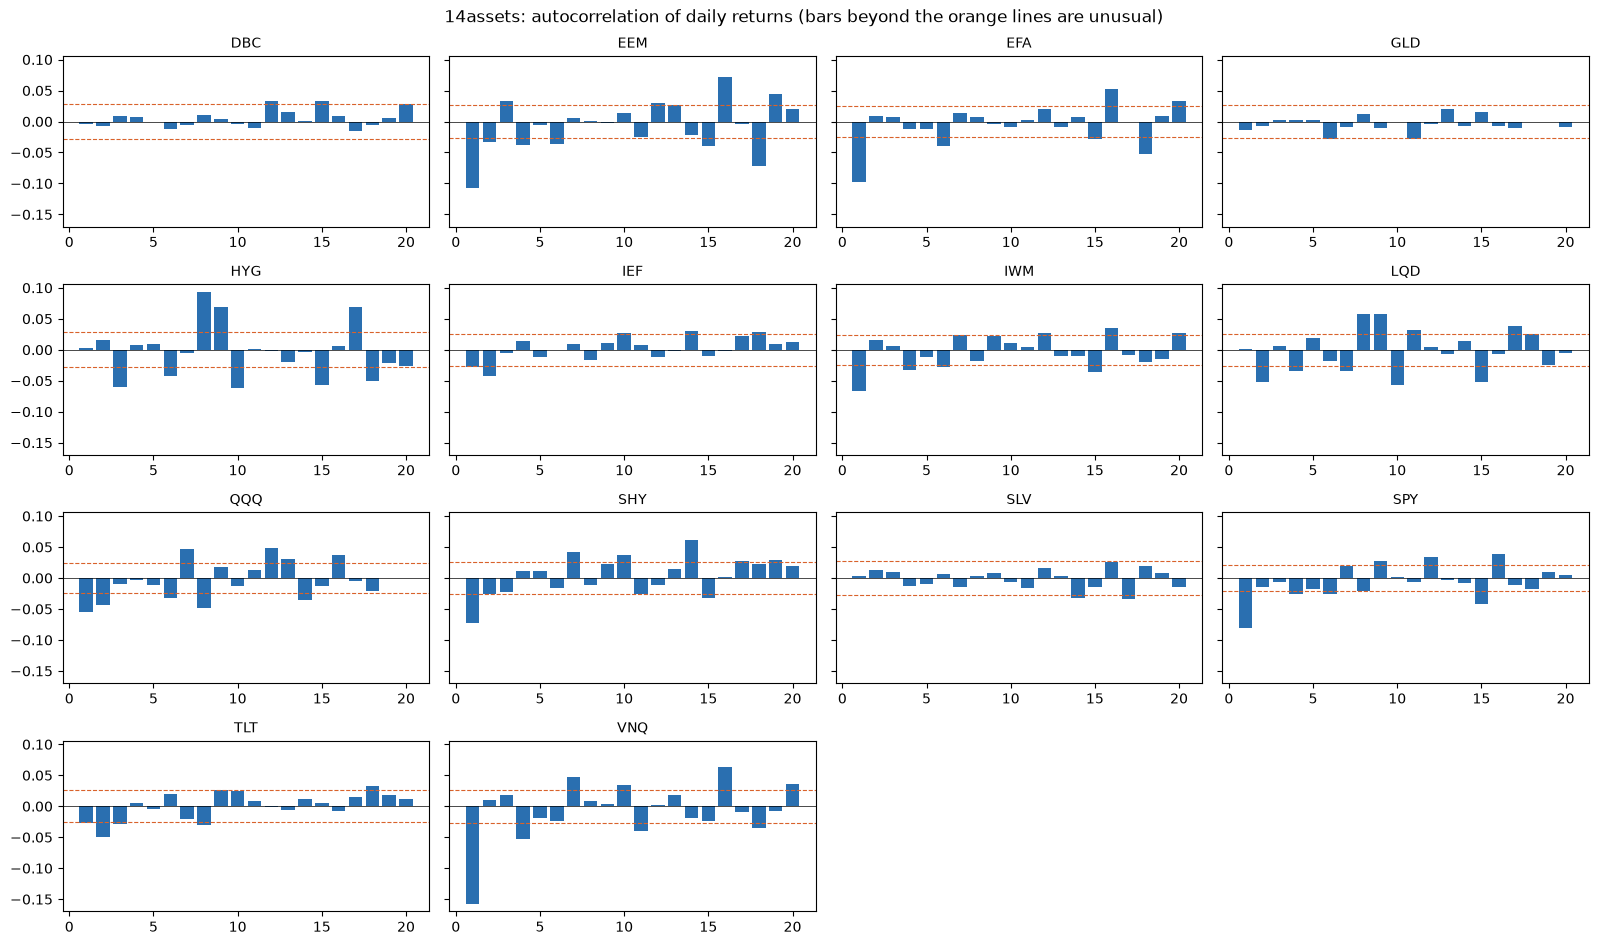


===== 10sectors =====
        days  acf_lag1  pacf_lag1  lags_outside_band_of_20  LjungBox10_p  LjungBox20_p  AR1_phi   AR1_t  AR1_t_robust
XLE   6797.0   -0.0442    -0.0442                      5.0        0.0136           0.0  -0.0442 -3.6437       -1.9358
XLF   6797.0   -0.0953    -0.0953                     10.0        0.0000           0.0  -0.0953 -7.8884       -3.2508
XLK   6797.0   -0.0666    -0.0666                      9.0        0.0000           0.0  -0.0666 -5.5002       -3.0793
XLV   6797.0   -0.0335    -0.0335                      7.0        0.0001           0.0  -0.0335 -2.7619       -1.4026
XLI   6797.0   -0.0338    -0.0338                      7.0        0.0000           0.0  -0.0338 -2.7896       -1.5235
XLP   6797.0   -0.0759    -0.0759                      7.0        0.0000           0.0  -0.0759 -6.2784       -2.8733
XLY   6797.0   -0.0272    -0.0272                      6.0        0.0020           0.0  -0.0272 -2.2396       -1.3441
XLU   6797.0   -0.0775    -0.0775

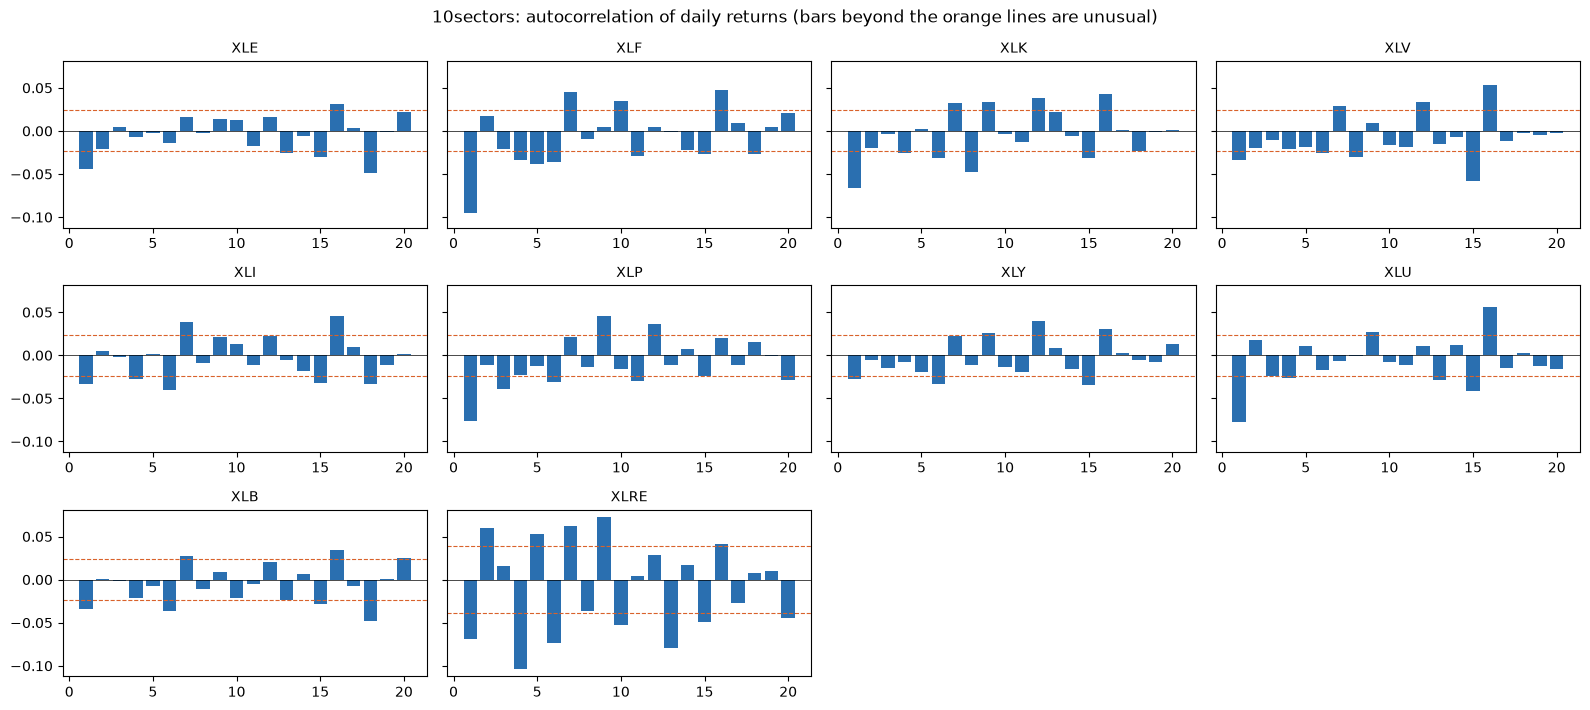

In [3]:
part1 = {}

for name, returns in returns_all.items():
    rows = {}
    acfs = {}
    for etf in returns.columns:
        r = own_history(returns[etf]).to_numpy()
        n = len(r)
        rho = acf(r, MAX_LAG)
        pa = pacf(r, MAX_LAG)
        band = 1.96 / np.sqrt(n)
        _, p_lb10 = ljung_box(rho, n, 10)
        _, p_lb20 = ljung_box(rho, n, 20)
        phi, t_normal, t_robust = ar1_fit(r[1:], r[:-1])
        acfs[etf] = (rho, band)
        rows[etf] = {
            "days": n,
            "acf_lag1": rho[0],
            "pacf_lag1": pa[0],
            "lags_outside_band_of_20": int(np.sum(np.abs(rho) > band)),
            "LjungBox10_p": p_lb10,
            "LjungBox20_p": p_lb20,
            "AR1_phi": phi,
            "AR1_t": t_normal,
            "AR1_t_robust": t_robust,
        }
    table = pd.DataFrame(rows).T.astype(float)
    part1[name] = table
    table.to_csv(RESULTS / f"part1_acf_ar1_{name}.csv")

    print(f"\n===== {name} =====")
    print(table.round(4).to_string())
    print(f"\nphi negative (bounce-back):               {int((table['AR1_phi'] < 0).sum())} of {len(table)}")
    print(f"Ljung-Box(20) p < 0.05:                   {int((table['LjungBox20_p'] < 0.05).sum())} of {len(table)} (luck alone: about {0.05 * len(table):.1f})")
    print(f"phi significant with robust t (|t| > 1.96): {int((table['AR1_t_robust'].abs() > 1.96).sum())} of {len(table)}")
    print(f"typical size of phi: {table['AR1_phi'].median():.3f}  -> explains only about {100 * table['AR1_phi'].median() ** 2:.2f}% of a day's variance")

    # chart: ACF bars of every ETF
    cols = 4
    nrows = int(np.ceil(len(acfs) / cols))
    fig, axes = plt.subplots(nrows, cols, figsize = (4 * cols, 2.4 * nrows), sharey = True)
    axes = np.atleast_1d(axes).ravel()
    for ax, (etf, (rho, band)) in zip(axes, acfs.items()):
        ax.bar(range(1, MAX_LAG + 1), rho, color = BLUE)
        ax.axhline(band, color = ORANGE, ls = "--", lw = 0.8)
        ax.axhline(-band, color = ORANGE, ls = "--", lw = 0.8)
        ax.axhline(0, color = "black", lw = 0.5)
        ax.set_title(etf, fontsize = 10)
    for ax in axes[len(acfs):]:
        ax.axis("off")
    fig.suptitle(f"{name}: autocorrelation of daily returns (bars beyond the orange lines are unusual)")
    fig.tight_layout()
    fig.savefig(RESULTS / f"part1_acf_{name}.png", dpi = 110)
    plt.show()

## Step 3 - Part 1: ADF test
**Idea:** does the price wander like a drunk person's walk (a *random walk*), which can't be predicted?
- ADF value **above -2.86** -> cannot reject random walk (this is what we expect for prices).
- ADF value **below -2.86** -> not a random walk (this is what we expect for returns).

In [4]:
# Critical values (with constant): 1% = -3.43, 5% = -2.86, 10% = -2.57
# ADF statistic ABOVE -2.86 -> cannot reject "random walk".  BELOW -2.86 -> stationary.
adf_all = {}

for name, returns in returns_all.items():
    rows = {}
    for etf in returns.columns:
        r = own_history(returns[etf])
        log_price = r.cumsum().to_numpy()
        adf_price = adf_stat(log_price, lags = 5)
        adf_return = adf_stat(r.to_numpy(), lags = 5)
        rows[etf] = {
            "ADF_price": adf_price,
            "price_is_random_walk": int(adf_price > -2.86),
            "ADF_return": adf_return,
            "return_is_stationary": int(adf_return < -2.86),
        }
    table = pd.DataFrame(rows).T.astype(float)
    adf_all[name] = table
    table.to_csv(RESULTS / f"part1_adf_{name}.csv")

    print(f"\n===== {name} =====")
    print(table.round(3).to_string())
    print(f"\nprices look like a random walk: {int(table['price_is_random_walk'].sum())} of {len(table)}")
    print(f"returns are stationary:         {int(table['return_is_stationary'].sum())} of {len(table)}")


===== 14assets =====
     ADF_price  price_is_random_walk  ADF_return  return_is_stationary
DBC     -1.516                   1.0     -29.115                   1.0
EEM     -3.185                   0.0     -33.817                   1.0
EFA     -0.737                   1.0     -34.355                   1.0
GLD     -0.439                   1.0     -30.505                   1.0
HYG     -0.734                   1.0     -29.606                   1.0
IEF     -1.815                   1.0     -32.102                   1.0
IWM     -0.466                   1.0     -35.072                   1.0
LQD     -1.470                   1.0     -32.675                   1.0
QQQ      0.900                   1.0     -36.274                   1.0
SHY     -1.455                   1.0     -32.425                   1.0
SLV     -0.677                   1.0     -28.672                   1.0
SPY     -0.001                   1.0     -40.693                   1.0
TLT     -1.913                   1.0     -31.987       

## Step 4 - Part 2: ARCH test and GARCH(1,1)
**Idea:** wild days follow wild days.
- **ARCH p < 0.05** = volatility clusters.
- **alpha** = how strongly yesterday's shock moves today's volatility. **beta** = memory of old volatility. **persistence = alpha + beta**; near 1 means shocks fade slowly. **half_life** = days for a shock to fade by half.


===== 14assets =====
     ARCH_test_p   alpha    beta  persistence  half_life_days  ARCH_test_p_after_GARCH
DBC          0.0  0.0621  0.9298       0.9919         84.8540                   0.3046
EEM          0.0  0.0989  0.8822       0.9812         36.4548                   0.0995
EFA          0.0  0.1119  0.8749       0.9868         52.3368                   0.3478
GLD          0.0  0.0577  0.9316       0.9893         64.5926                   0.5734
HYG          0.0  0.1481  0.8518       0.9999             NaN                   0.0000
IEF          0.0  0.0468  0.9466       0.9935        105.6051                   0.3472
IWM          0.0  0.0893  0.8908       0.9801         34.5317                   0.0177
LQD          0.0  0.0951  0.8936       0.9887         61.0495                   0.1300
QQQ          0.0  0.1019  0.8881       0.9900         69.0282                   0.0297
SHY          0.0  0.0602  0.9397       0.9999             NaN                   0.0022
SLV          0.0  0.0

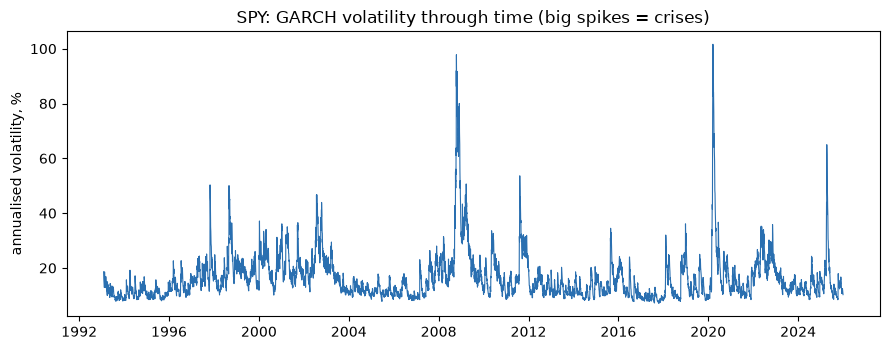


===== 10sectors =====
      ARCH_test_p   alpha    beta  persistence  half_life_days  ARCH_test_p_after_GARCH
XLE           0.0  0.0774  0.9149       0.9923         89.7960                   0.2593
XLF           0.0  0.1144  0.8733       0.9878         56.3475                   0.0683
XLK           0.0  0.0994  0.8920       0.9914         79.9641                   0.0449
XLV           0.0  0.1030  0.8772       0.9802         34.6940                   0.3835
XLI           0.0  0.0993  0.8842       0.9835         41.6636                   0.3473
XLP           0.0  0.1001  0.8831       0.9832         40.9627                   0.1788
XLY           0.0  0.0952  0.8969       0.9921         87.3898                   0.4294
XLU           0.0  0.0879  0.8976       0.9855         47.3111                   0.0007
XLB           0.0  0.0933  0.8937       0.9870         52.8327                   0.1194
XLRE          0.0  0.0911  0.8910       0.9821         38.3234                   0.7911

ARCH eff

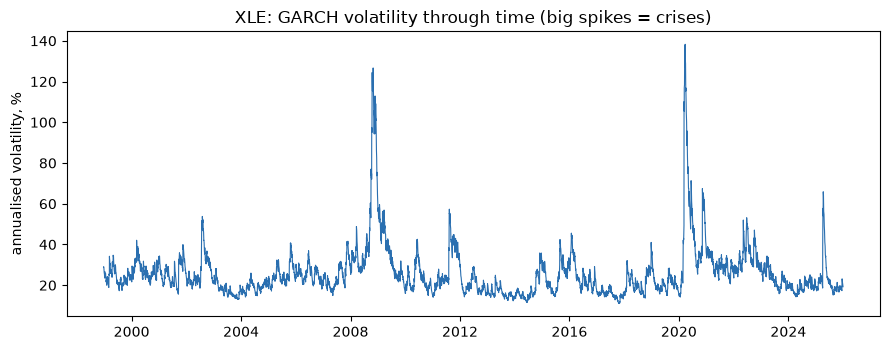

In [5]:
garch_all = {}
sigma_all = {}

for name, returns in returns_all.items():
    rows = {}
    sigmas = {}
    for etf in returns.columns:
        r_pct = own_history(returns[etf]).mul(100)
        _, p_arch = arch_lm(r_pct.to_numpy(), lags = 5)
        g = garch11(r_pct.to_numpy())
        _, p_after = arch_lm(g["std_resid"], lags = 5)
        sigmas[etf] = pd.Series(g["sigma"], index = r_pct.index)
        rows[etf] = {
            "ARCH_test_p": p_arch,
            "alpha": g["alpha"],
            "beta": g["beta"],
            "persistence": g["persistence"],
            "half_life_days": g["half_life"],
            "ARCH_test_p_after_GARCH": p_after,
        }
    table = pd.DataFrame(rows).T.astype(float)
    garch_all[name] = table
    sigma_all[name] = pd.DataFrame(sigmas)
    table.to_csv(RESULTS / f"part2_garch_{name}.csv")

    print(f"\n===== {name} =====")
    print(table.round(4).to_string())
    print(f"\nARCH effect present (p < 0.05):  {int((table['ARCH_test_p'] < 0.05).sum())} of {len(table)}")
    print(f"typical persistence alpha+beta:  {table['persistence'].median():.3f}")
    print(f"typical half-life of a shock:    {table['half_life_days'].median():.0f} days")
    print("(alpha = reaction to yesterday's shock, beta = memory of old volatility; "
          "persistence near 1 = shocks fade very slowly)")

    pick = "SPY" if "SPY" in sigmas else list(sigmas)[0]
    fig, ax = plt.subplots(figsize = (9, 3.6))
    ax.plot(sigmas[pick].index, sigmas[pick].values * np.sqrt(252), color = BLUE, lw = 0.8)
    ax.set_ylabel("annualised volatility, %")
    ax.set_title(f"{pick}: GARCH volatility through time (big spikes = crises)")
    fig.tight_layout()
    fig.savefig(RESULTS / f"part2_garch_vol_{name}.png", dpi = 110)
    plt.show()

## Step 5 - Part 2: does a GARCH regime agree with the project's `vol_regime`?
`vol_regime` = 21-day std / 252-day std, HIGH if above its expanding median.
- **agree %** = share of days with the same HIGH/LOW label. **kappa** = agreement beyond luck (0 = luck, 1 = identical).
- *Ratio* version uses the same shape as `vol_regime`, so it is the fair comparison.


===== 14assets =====
     days_compared  agree_level_pct  kappa_level  agree_ratio_pct  kappa_ratio
DBC         4506.0           66.289        0.319           84.820        0.697
EEM         5215.0           66.194        0.328           88.169        0.763
EFA         5626.0           65.784        0.316           87.202        0.744
GLD         4810.0           72.890        0.450           86.195        0.725
HYG         4210.0           67.007        0.339           88.052        0.761
IEF         5394.0           67.316        0.344           82.907        0.658
IWM         5935.0           70.834        0.418           85.527        0.710
LQD         5394.0           63.293        0.263           83.964        0.679
QQQ         6243.0           64.873        0.293           86.785        0.736
SHY         5394.0           56.915        0.117           87.468        0.749
SLV         4448.0           67.896        0.363           85.791        0.715
SPY         7785.0           6

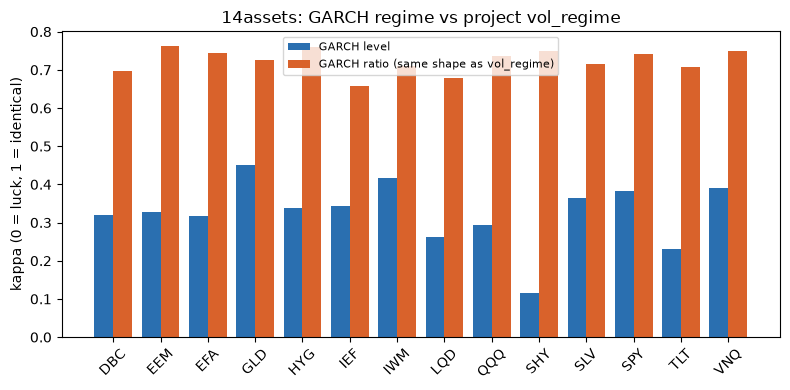


===== 10sectors =====
      days_compared  agree_level_pct  kappa_level  agree_ratio_pct  kappa_ratio
XLE          6295.0           69.134        0.374           89.198        0.781
XLF          6295.0           69.118        0.376           85.512        0.710
XLK          6295.0           64.925        0.289           87.101        0.742
XLV          6295.0           69.500        0.392           86.291        0.726
XLI          6295.0           69.468        0.382           85.004        0.700
XLP          6295.0           69.865        0.395           85.496        0.710
XLY          6295.0           70.294        0.391           87.816        0.755
XLU          6295.0           70.485        0.403           87.244        0.745
XLB          6295.0           68.801        0.356           87.021        0.741
XLRE         2070.0           68.213        0.354           85.024        0.702

average agreement, GARCH level version: 69%  (kappa 0.37)
average agreement, GARCH ratio version

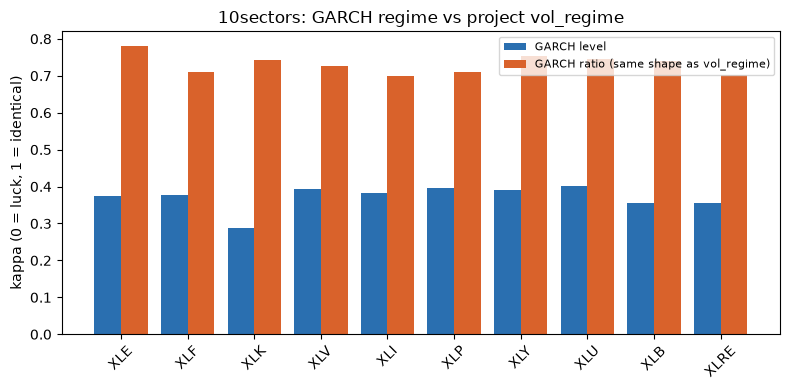

In [6]:
# vol_regime (project) = 21-day std / 252-day std, HIGH if above its expanding median.
# Version A: GARCH volatility level, HIGH if above its own expanding median.
# Version B: GARCH volatility / 252-day std, HIGH if above its expanding median (same shape as vol_regime).
# agreement = % of days with the same label.  kappa = agreement beyond luck (0 = luck, 1 = identical).
agree_all = {}

for name, returns in returns_all.items():
    rows = {}
    for etf in returns.columns:
        r = own_history(returns[etf])
        sigma = sigma_all[name][etf].dropna()

        label_project = vol_regime_label(r)

        med_a = sigma.expanding(min_periods = 252).median()
        label_a = pd.Series(np.where(med_a.notna(), (sigma > med_a).astype(float), np.nan), index = sigma.index)

        ratio_b = (sigma / 100) / r.rolling(252).std()
        med_b = ratio_b.expanding(min_periods = 252).median()
        label_b = pd.Series(np.where(ratio_b.notna() & med_b.notna(), (ratio_b > med_b).astype(float), np.nan),
                            index = sigma.index)

        both = pd.concat([label_project, label_a, label_b], axis = 1, keys = ["p", "a", "b"]).dropna()
        agree_a, kappa_a = cohen_kappa(both["p"], both["a"])
        agree_b, kappa_b = cohen_kappa(both["p"], both["b"])
        rows[etf] = {
            "days_compared": len(both),
            "agree_level_pct": 100 * agree_a, "kappa_level": kappa_a,
            "agree_ratio_pct": 100 * agree_b, "kappa_ratio": kappa_b,
        }
    table = pd.DataFrame(rows).T.astype(float)
    agree_all[name] = table
    table.to_csv(RESULTS / f"part2_regime_agreement_{name}.csv")

    print(f"\n===== {name} =====")
    print(table.round(3).to_string())
    print(f"\naverage agreement, GARCH level version: {table['agree_level_pct'].mean():.0f}%  (kappa {table['kappa_level'].mean():.2f})")
    print(f"average agreement, GARCH ratio version: {table['agree_ratio_pct'].mean():.0f}%  (kappa {table['kappa_ratio'].mean():.2f})")

    fig, ax = plt.subplots(figsize = (8, 4))
    x = np.arange(len(table))
    ax.bar(x - 0.2, table["kappa_level"], width = 0.4, color = BLUE, label = "GARCH level")
    ax.bar(x + 0.2, table["kappa_ratio"], width = 0.4, color = ORANGE, label = "GARCH ratio (same shape as vol_regime)")
    ax.axhline(0, color = "black", lw = 0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(table.index, rotation = 45)
    ax.set_ylabel("kappa (0 = luck, 1 = identical)")
    ax.set_title(f"{name}: GARCH regime vs project vol_regime")
    ax.legend(fontsize = 8)
    fig.tight_layout()
    fig.savefig(RESULTS / f"part2_kappa_{name}.png", dpi = 110)
    plt.show()

## Step 6 - Overview
Every number below is computed from the steps above.

In [7]:
print("\n" + "=" * 70)
print("OVERVIEW")
print("=" * 70)
for name in returns_all:
    a, d, g, k = part1[name], adf_all[name], garch_all[name], agree_all[name]
    n = len(a)
    print(f"\n--- {name} ({n} ETFs) ---")
    print("PART 1 - is there anything to harvest day to day?")
    print(f"  lag-1 autocorrelation negative in {int((a['acf_lag1'] < 0).sum())} of {n}, typical size {a['acf_lag1'].median():.3f} "
          f"(about {100 * a['AR1_phi'].median() ** 2:.2f}% of a day's variance)")
    print(f"  Ljung-Box(20) rejects 'no autocorrelation' in {int((a['LjungBox20_p'] < 0.05).sum())} of {n}")
    print(f"  but with a robust t-stat only {int((a['AR1_t_robust'].abs() > 1.96).sum())} of {n} stay significant")
    print(f"  ADF: prices look like random walks in {int(d['price_is_random_walk'].sum())} of {n}; returns are stationary in {int(d['return_is_stationary'].sum())} of {n}")
    print("PART 2 - volatility")
    print(f"  ARCH effect in {int((g['ARCH_test_p'] < 0.05).sum())} of {n}; typical persistence {g['persistence'].median():.3f}; "
          f"typical half-life {g['half_life_days'].median():.0f} days")
    print(f"  GARCH 'level' regime vs vol_regime: agreement {k['agree_level_pct'].mean():.0f}%, kappa {k['kappa_level'].mean():.2f}")
    print(f"  GARCH 'ratio' regime (same shape as vol_regime): agreement {k['agree_ratio_pct'].mean():.0f}%, kappa {k['kappa_ratio'].mean():.2f}")
print("\nCharts and tables are saved in the folder:", RESULTS)


OVERVIEW

--- 14assets (14 ETFs) ---
PART 1 - is there anything to harvest day to day?
  lag-1 autocorrelation negative in 11 of 14, typical size -0.041 (about 0.17% of a day's variance)
  Ljung-Box(20) rejects 'no autocorrelation' in 11 of 14
  but with a robust t-stat only 7 of 14 stay significant
  ADF: prices look like random walks in 13 of 14; returns are stationary in 14 of 14
PART 2 - volatility
  ARCH effect in 14 of 14; typical persistence 0.990; typical half-life 64 days
  GARCH 'level' regime vs vol_regime: agreement 66%, kappa 0.33
  GARCH 'ratio' regime (same shape as vol_regime): agreement 86%, kappa 0.72

--- 10sectors (10 ETFs) ---
PART 1 - is there anything to harvest day to day?
  lag-1 autocorrelation negative in 10 of 10, typical size -0.055 (about 0.31% of a day's variance)
  Ljung-Box(20) rejects 'no autocorrelation' in 10 of 10
  but with a robust t-stat only 4 of 10 stay significant
  ADF: prices look like random walks in 10 of 10; returns are stationary in 10 